# LOBSTER
load and investigate a sample of LOBSTER data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
message_file = 'AAPL_2026-03-04_2026-03-04_10/AAPL_2026-03-04_34140000_57660000_message_10.csv' 
orderbook_file='AAPL_2026-03-04_2026-03-04_10/AAPL_2026-03-04_34140000_57660000_orderbook_10.csv'

# Reading a CSV file into a DataFrame
df_m = pd.read_csv(message_file)
#print(df.head())

C:\cygwin64\tmp\ipykernel_15096\2137873401.py:5: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df_m = pd.read_csv(message_file)


In [3]:
print(df_m.shape)
print(df_m.head(2))
print(df_m.columns)

(2146723, 7)
   11098.165652389  7      0  0.1        1  -1 null
0     14400.017165  1  22509  100  2622800   1  NaN
1     14400.017277  1  22561  100  2632100  -1  NaN
Index(['11098.165652389', '7', '0', '0.1', '1', '-1', 'null'], dtype='object')


In [4]:
# Add column names
df_m.columns = ['Time', 'Event Type','Order ID','Size','Price','Direction','Unknown']
print(df_m.head(2))

           Time  Event Type  Order ID  Size    Price  Direction Unknown
0  14400.017165           1     22509   100  2622800          1     NaN
1  14400.017277           1     22561   100  2632100         -1     NaN


In [5]:
m_timestamps = df_m['Time']
print(type(m_timestamps))
print(m_timestamps.shape)
print(m_timestamps.shape[0])

<class 'pandas.core.series.Series'>
(2146723,)
2146723


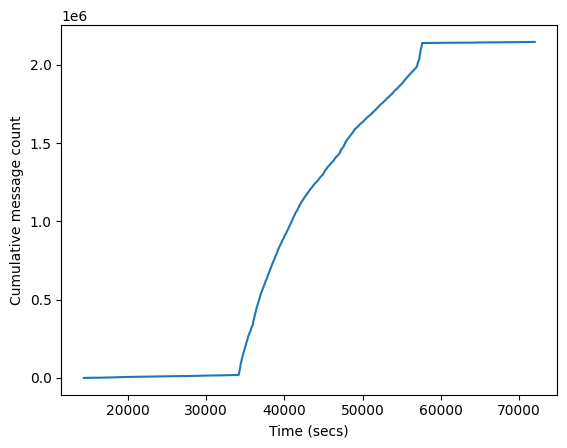

In [7]:
num_m = m_timestamps.shape[0]

plt.plot(m_timestamps,range(0,num_m))
plt.xlabel('Time (secs)')
plt.ylabel('Cumulative message count')
plt.show()

In [10]:
m_price = df_m['Price']
print(type(m_price))
print(m_price.shape)
print(m_price.shape[0])

<class 'pandas.core.series.Series'>
(2146723,)
2146723


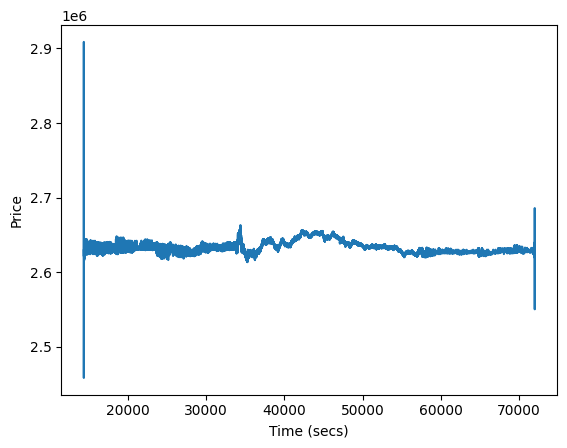

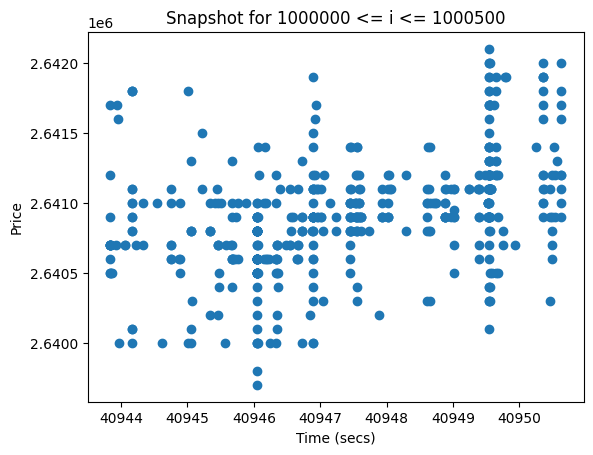

In [11]:
plt.plot(m_timestamps, m_price)
plt.xlabel('Time (secs)')
plt.ylabel('Price')
plt.show()

i_min = 1000000
i_max = i_min + 500
this_title = "Snapshot for " + str(i_min) + " <= i <= " + str(i_max) 
plt.scatter(m_timestamps.iloc[i_min : i_max], m_price.iloc[i_min : i_max])
plt.xlabel('Time (secs)')
plt.ylabel('Price')
plt.title(this_title)
plt.show()

In [12]:
m_size = df_m['Size']
print(type(m_size))
print(m_size.shape)
print(m_size.shape[0])

<class 'pandas.core.series.Series'>
(2146723,)
2146723


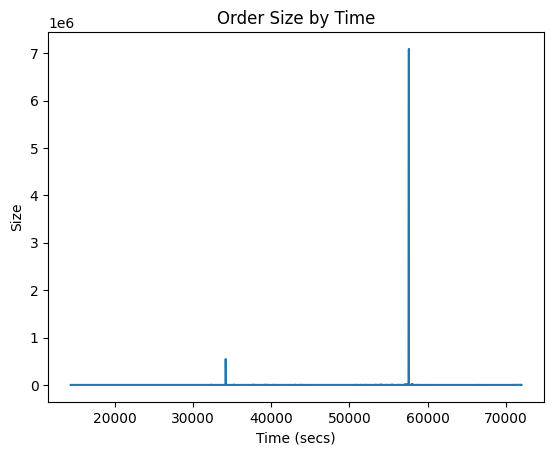

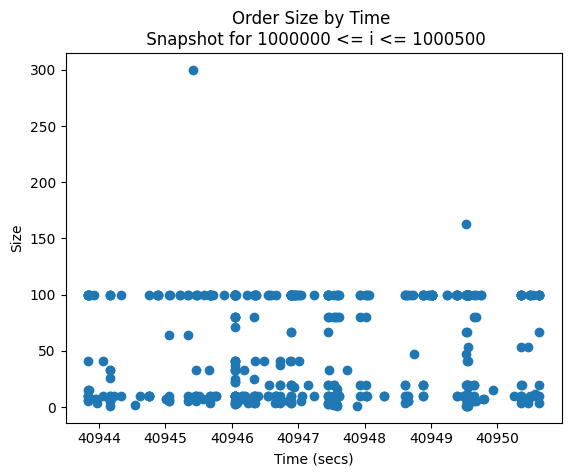

In [13]:
plt.plot(m_timestamps, m_size)
plt.xlabel('Time (secs)')
plt.ylabel('Size')
plt.title('Order Size by Time')
plt.show()

i_min = 1000000
i_max = i_min + 500
this_title = "Order Size by Time \n Snapshot for " + str(i_min) + " <= i <= " + str(i_max)
plt.scatter(m_timestamps.iloc[i_min : i_max], m_size.iloc[i_min : i_max])
plt.xlabel('Time (secs)')
plt.ylabel('Size')
plt.title(this_title)
plt.show()

In [14]:
df_m['Event Type'] = df_m['Event Type'].astype('category')

In [15]:
print(df_m.columns)

Index(['Time', 'Event Type', 'Order ID', 'Size', 'Price', 'Direction',
       'Unknown'],
      dtype='object')


In [19]:
# Group by the categorical column and aggregate
grouped = df_m.groupby('Event Type', observed=True).agg({
    'Time': ['count'],  'Event Type' : ['count'],  
    'Order ID': ['count'],  'Size': ['count'],    
    'Price': ['count'],  'Direction' : ['count'], 
    'Unknown': ['count']
})

### Now let's look at the orderbook

In [20]:
df_ob=pd.read_csv(orderbook_file)

In [21]:
print(df_ob.shape)
print(df_ob.head(2))
print(df_ob.columns)

(2146723, 40)
   9999999999    0  -9999999999  0.1  9999999999.1  0.2  -9999999999.1  0.3  \
0  9999999999    0      2622800  100    9999999999    0    -9999999999    0   
1     2632100  100      2622800  100    9999999999    0    -9999999999    0   

   9999999999.2  0.4  ...  -9999999999.7  0.15  9999999999.8  0.16  \
0    9999999999    0  ...    -9999999999     0    9999999999     0   
1    9999999999    0  ...    -9999999999     0    9999999999     0   

   -9999999999.8  0.17  9999999999.9  0.18  -9999999999.9  0.19  
0    -9999999999     0    9999999999     0    -9999999999     0  
1    -9999999999     0    9999999999     0    -9999999999     0  

[2 rows x 40 columns]
Index(['9999999999', '0', '-9999999999', '0.1', '9999999999.1', '0.2',
       '-9999999999.1', '0.3', '9999999999.2', '0.4', '-9999999999.2', '0.5',
       '9999999999.3', '0.6', '-9999999999.3', '0.7', '9999999999.4', '0.8',
       '-9999999999.4', '0.9', '9999999999.5', '0.10', '-9999999999.5', '0.11',
       '99

In [22]:
# Add column names
df_ob.columns=[
"AskPrice1",
"AskSize1",
"BidPrice1",
"BidSize1",
"AskPrice2",
"AskSize2",
"BidPrice2",
"BidSize2",
"AskPrice3",
"AskSize3",
"BidPrice3",
"BidSize3",
"AskPrice4",
"AskSize4",
"BidPrice4",
"BidSize4",
"AskPrice5",
"AskSize5",
"BidPrice5",
"BidSize5",
"AskPrice6",
"AskSize6",
"BidPrice6",
"BidSize6",
"AskPrice7",
"AskSize7",
"BidPrice7",
"BidSize7",
"AskPrice8",
"AskSize8",
"BidPrice8",
"BidSize8",
"AskPrice9",
"AskSize9",
"BidPrice9",
"BidSize9",
"AskPrice10",
"AskSize10",
"BidPrice10",
"BidSize10",
]
print(df_ob.head(2))

    AskPrice1  AskSize1  BidPrice1  BidSize1   AskPrice2  AskSize2  \
0  9999999999         0    2622800       100  9999999999         0   
1     2632100       100    2622800       100  9999999999         0   

    BidPrice2  BidSize2   AskPrice3  AskSize3  ...   BidPrice8  BidSize8  \
0 -9999999999         0  9999999999         0  ... -9999999999         0   
1 -9999999999         0  9999999999         0  ... -9999999999         0   

    AskPrice9  AskSize9   BidPrice9  BidSize9  AskPrice10  AskSize10  \
0  9999999999         0 -9999999999         0  9999999999          0   
1  9999999999         0 -9999999999         0  9999999999          0   

   BidPrice10  BidSize10  
0 -9999999999          0  
1 -9999999999          0  

[2 rows x 40 columns]


In [23]:
ob_AP1 = df_ob['AskPrice1']
ob_BP1 = df_ob['BidPrice1']

ob_AP1 = df_ob['AskPrice1']
ob_BP1 = df_ob['BidPrice1']

ob_AP2 = df_ob['AskPrice2']
ob_BP2 = df_ob['BidPrice2']

ob_AP3 = df_ob['AskPrice3']
ob_BP3 = df_ob['BidPrice3']

ob_AP4 = df_ob['AskPrice4']
ob_BP4 = df_ob['BidPrice4']

ob_AP5 = df_ob['AskPrice5']
ob_BP5 = df_ob['BidPrice5']

ob_AP6 = df_ob['AskPrice6']
ob_BP6 = df_ob['BidPrice6']

ob_AP7 = df_ob['AskPrice7']
ob_BP7 = df_ob['BidPrice7']

ob_AP8 = df_ob['AskPrice8']
ob_BP8 = df_ob['BidPrice8']

ob_AP9 = df_ob['AskPrice9']
ob_BP9 = df_ob['BidPrice9']

ob_AP10 = df_ob['AskPrice10']
ob_BP10 = df_ob['BidPrice10']

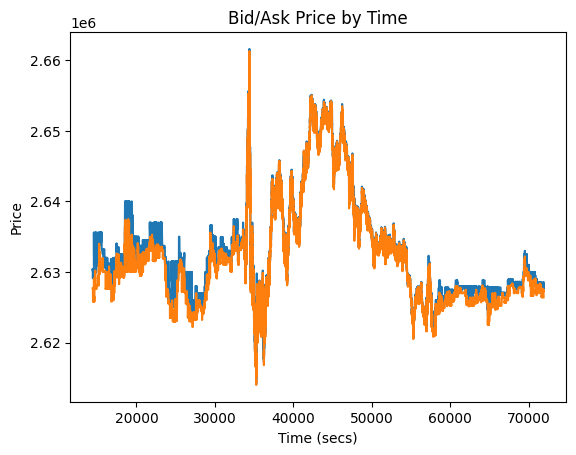

In [25]:
k = 100

plt.plot(m_timestamps[k:-k], ob_AP1[k:-k], label = "AskPrice1")
plt.plot(m_timestamps[k:-k], ob_BP1[k:-k], label = "BidPrice1")
plt.xlabel('Time (secs)')
plt.ylabel('Price')
plt.title('Bid/Ask Price by Time')
plt.show()

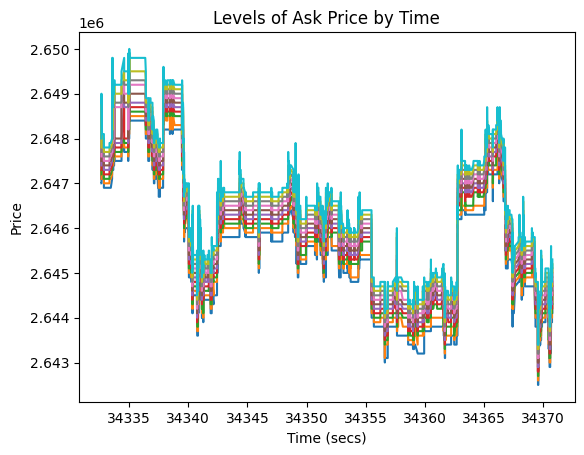

In [26]:
i_min = 55000
i_max = 65000
plt.plot(m_timestamps[i_min:i_max], ob_AP1[i_min:i_max], label = "AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP2[i_min:i_max], label = "AskPrice2")
plt.plot(m_timestamps[i_min:i_max], ob_AP3[i_min:i_max], label = "AskPrice3")
plt.plot(m_timestamps[i_min:i_max], ob_AP4[i_min:i_max], label = "AskPrice4")
plt.plot(m_timestamps[i_min:i_max], ob_AP5[i_min:i_max], label = "AskPrice5")
plt.plot(m_timestamps[i_min:i_max], ob_AP6[i_min:i_max], label = "AskPrice6")
plt.plot(m_timestamps[i_min:i_max], ob_AP7[i_min:i_max], label = "AskPrice7")
plt.plot(m_timestamps[i_min:i_max], ob_AP8[i_min:i_max], label = "AskPrice8")
plt.plot(m_timestamps[i_min:i_max], ob_AP9[i_min:i_max], label = "AskPrice9")
plt.plot(m_timestamps[i_min:i_max], ob_AP10[i_min:i_max], label = "AskPrice10")
plt.xlabel('Time (secs)')
plt.ylabel('Price')
plt.title('Levels of Ask Price by Time')
plt.show()

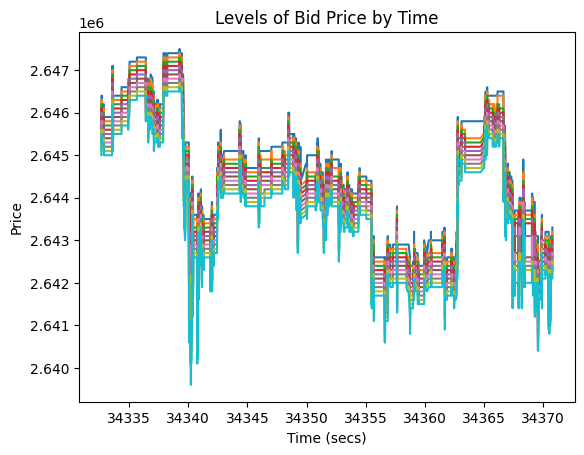

In [27]:
i_min = 55000
i_max = 65000
plt.plot(m_timestamps[i_min:i_max], ob_BP1[i_min:i_max], label = "BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP2[i_min:i_max], label = "BidPrice2")
plt.plot(m_timestamps[i_min:i_max], ob_BP3[i_min:i_max], label = "BidPrice3")
plt.plot(m_timestamps[i_min:i_max], ob_BP4[i_min:i_max], label = "BidPrice4")
plt.plot(m_timestamps[i_min:i_max], ob_BP5[i_min:i_max], label = "BidPrice5")
plt.plot(m_timestamps[i_min:i_max], ob_BP6[i_min:i_max], label = "BidPrice6")
plt.plot(m_timestamps[i_min:i_max], ob_BP7[i_min:i_max], label = "BidPrice7")
plt.plot(m_timestamps[i_min:i_max], ob_BP8[i_min:i_max], label = "BidPrice8")
plt.plot(m_timestamps[i_min:i_max], ob_BP9[i_min:i_max], label = "BidPrice9")
plt.plot(m_timestamps[i_min:i_max], ob_BP10[i_min:i_max], label = "BidPrice10")
plt.xlabel('Time (secs)')
plt.ylabel('Price')
plt.title('Levels of Bid Price by Time')
plt.show()

<class 'pandas.core.series.Series'>


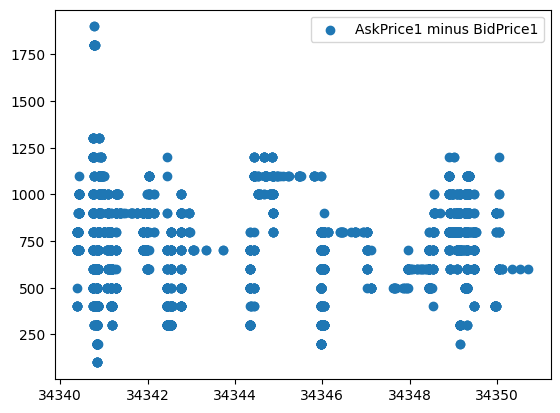

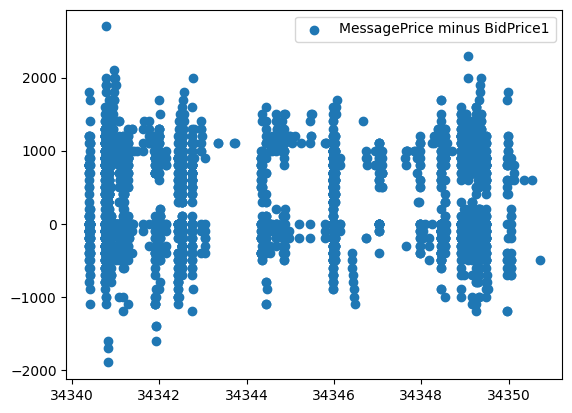

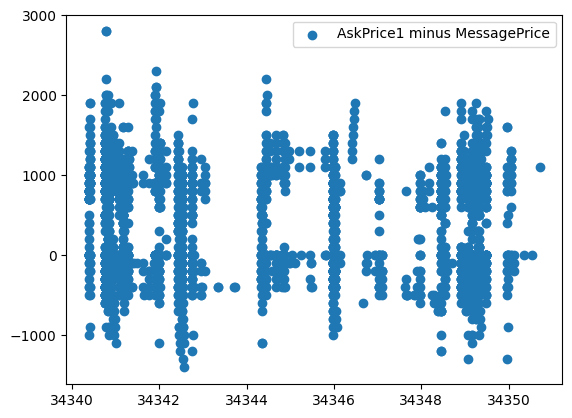

In [28]:
print(type(ob_BP1))
ob_AP1_minus_ob_BP1 = ob_AP1 - ob_BP1
m_price_minus_ob_BP1 = m_price - ob_BP1
ob_AP1_minus_m_price = ob_AP1 - m_price


i_min = 57000 #55000
i_max = 60000 # 65000
plt.scatter(m_timestamps[i_min:i_max], ob_AP1_minus_ob_BP1[i_min:i_max], label = "AskPrice1 minus BidPrice1")
#plt.scatter(m_timestamps[i_min:i_max], m_price_minus_ob_BP1[i_min:i_max], label = "MidPrice minus BidPrice1")
#plt.scatter(m_timestamps[i_min:i_max], ob_AP1_minus_m_price[i_min:i_max], label = "AskPrice1 minus MidPrice")
plt.legend()
plt.show()

#plt.scatter(m_timestamps[i_min:i_max], ob_AP1_minus_ob_BP1[i_min:i_max], label = "AskPrice1 minus BidPrice1")
plt.scatter(m_timestamps[i_min:i_max], m_price_minus_ob_BP1[i_min:i_max], label = "MessagePrice minus BidPrice1")
#plt.scatter(m_timestamps[i_min:i_max], ob_AP1_minus_m_price[i_min:i_max], label = "AskPrice1 minus MidPrice")
plt.legend()
plt.show()

#plt.scatter(m_timestamps[i_min:i_max], ob_AP1_minus_ob_BP1[i_min:i_max], label = "AskPrice1 minus BidPrice1")
#plt.scatter(m_timestamps[i_min:i_max], m_price_minus_ob_BP1[i_min:i_max], label = "MidPrice minus BidPrice1")
plt.scatter(m_timestamps[i_min:i_max], ob_AP1_minus_m_price[i_min:i_max], label = "AskPrice1 minus MessagePrice")
plt.legend()
plt.show()

In [29]:
ob_AP2_minus_ob_AP1 = ob_AP2 - ob_AP1
ob_AP3_minus_ob_AP1 = ob_AP3 - ob_AP1
ob_AP4_minus_ob_AP1 = ob_AP4 - ob_AP1
ob_AP5_minus_ob_AP1 = ob_AP5 - ob_AP1
ob_AP6_minus_ob_AP1 = ob_AP6 - ob_AP1
ob_AP7_minus_ob_AP1 = ob_AP7 - ob_AP1
ob_AP8_minus_ob_AP1 = ob_AP8 - ob_AP1
ob_AP9_minus_ob_AP1 = ob_AP9 - ob_AP1
ob_AP10_minus_ob_AP1 = ob_AP10 - ob_AP1

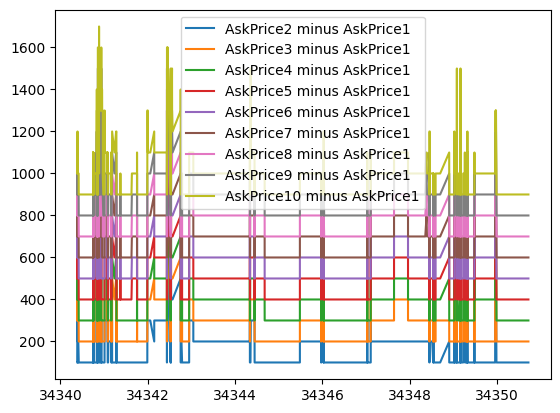

In [30]:
i_min = 57000 #55000
i_max = 60000 # 65000
plt.plot(m_timestamps[i_min:i_max], ob_AP2_minus_ob_AP1[i_min:i_max], label = "AskPrice2 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP3_minus_ob_AP1[i_min:i_max], label = "AskPrice3 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP4_minus_ob_AP1[i_min:i_max], label = "AskPrice4 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP5_minus_ob_AP1[i_min:i_max], label = "AskPrice5 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP6_minus_ob_AP1[i_min:i_max], label = "AskPrice6 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP7_minus_ob_AP1[i_min:i_max], label = "AskPrice7 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP8_minus_ob_AP1[i_min:i_max], label = "AskPrice8 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP9_minus_ob_AP1[i_min:i_max], label = "AskPrice9 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP10_minus_ob_AP1[i_min:i_max], label = "AskPrice10 minus AskPrice1")
plt.legend()
plt.show()

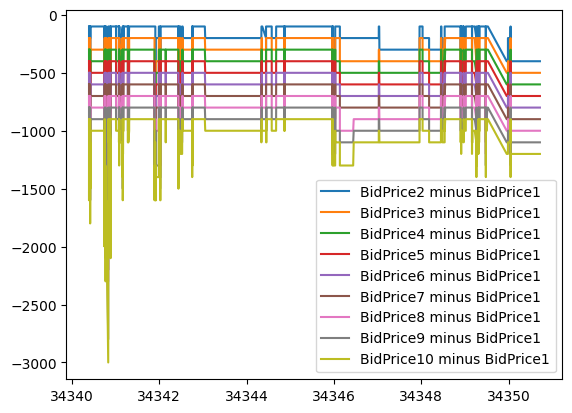

In [31]:
ob_BP2_minus_ob_BP1 = ob_BP2 - ob_BP1
ob_BP3_minus_ob_BP1 = ob_BP3 - ob_BP1
ob_BP4_minus_ob_BP1 = ob_BP4 - ob_BP1
ob_BP5_minus_ob_BP1 = ob_BP5 - ob_BP1
ob_BP6_minus_ob_BP1 = ob_BP6 - ob_BP1
ob_BP7_minus_ob_BP1 = ob_BP7 - ob_BP1
ob_BP8_minus_ob_BP1 = ob_BP8 - ob_BP1
ob_BP9_minus_ob_BP1 = ob_BP9 - ob_BP1
ob_BP10_minus_ob_BP1 = ob_BP10 - ob_BP1

i_min = 57000 #55000
i_max = 60000 # 65000
plt.plot(m_timestamps[i_min:i_max], ob_BP2_minus_ob_BP1[i_min:i_max], label = "BidPrice2 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP3_minus_ob_BP1[i_min:i_max], label = "BidPrice3 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP4_minus_ob_BP1[i_min:i_max], label = "BidPrice4 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP5_minus_ob_BP1[i_min:i_max], label = "BidPrice5 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP6_minus_ob_BP1[i_min:i_max], label = "BidPrice6 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP7_minus_ob_BP1[i_min:i_max], label = "BidPrice7 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP8_minus_ob_BP1[i_min:i_max], label = "BidPrice8 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP9_minus_ob_BP1[i_min:i_max], label = "BidPrice9 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP10_minus_ob_BP1[i_min:i_max], label = "BidPrice10 minus BidPrice1")
plt.legend()
plt.show()

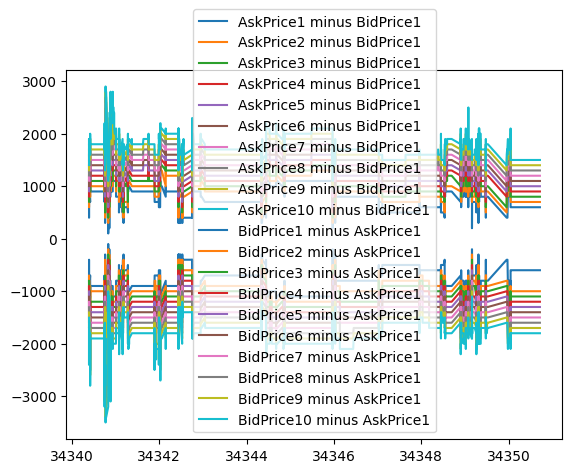

In [32]:
ob_BP1_minus_ob_AP1 = ob_BP1 - ob_AP1
ob_BP2_minus_ob_AP1 = ob_BP2 - ob_AP1
ob_BP3_minus_ob_AP1 = ob_BP3 - ob_AP1
ob_BP4_minus_ob_AP1 = ob_BP4 - ob_AP1
ob_BP5_minus_ob_AP1 = ob_BP5 - ob_AP1
ob_BP6_minus_ob_AP1 = ob_BP6 - ob_AP1
ob_BP7_minus_ob_AP1 = ob_BP7 - ob_AP1
ob_BP8_minus_ob_AP1 = ob_BP8 - ob_AP1
ob_BP9_minus_ob_AP1 = ob_BP9 - ob_AP1
ob_BP10_minus_ob_AP1 = ob_BP10 - ob_AP1

ob_AP1_minus_ob_BP1 = ob_AP1 - ob_BP1
ob_AP2_minus_ob_BP1 = ob_AP2 - ob_BP1
ob_AP3_minus_ob_BP1 = ob_AP3 - ob_BP1
ob_AP4_minus_ob_BP1 = ob_AP4 - ob_BP1
ob_AP5_minus_ob_BP1 = ob_AP5 - ob_BP1
ob_AP6_minus_ob_BP1 = ob_AP6 - ob_BP1
ob_AP7_minus_ob_BP1 = ob_AP7 - ob_BP1
ob_AP8_minus_ob_BP1 = ob_AP8 - ob_BP1
ob_AP9_minus_ob_BP1 = ob_AP9 - ob_BP1
ob_AP10_minus_ob_BP1 = ob_AP10 - ob_BP1

i_min = 57000 #55000
i_max = 60000 # 65000
plt.plot(m_timestamps[i_min:i_max], ob_AP1_minus_ob_BP1[i_min:i_max], label = "AskPrice1 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP2_minus_ob_BP1[i_min:i_max], label = "AskPrice2 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP3_minus_ob_BP1[i_min:i_max], label = "AskPrice3 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP4_minus_ob_BP1[i_min:i_max], label = "AskPrice4 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP5_minus_ob_BP1[i_min:i_max], label = "AskPrice5 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP6_minus_ob_BP1[i_min:i_max], label = "AskPrice6 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP7_minus_ob_BP1[i_min:i_max], label = "AskPrice7 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP8_minus_ob_BP1[i_min:i_max], label = "AskPrice8 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP9_minus_ob_BP1[i_min:i_max], label = "AskPrice9 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP10_minus_ob_BP1[i_min:i_max], label = "AskPrice10 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP1_minus_ob_AP1[i_min:i_max], label = "BidPrice1 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP2_minus_ob_AP1[i_min:i_max], label = "BidPrice2 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP3_minus_ob_AP1[i_min:i_max], label = "BidPrice3 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP4_minus_ob_AP1[i_min:i_max], label = "BidPrice4 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP5_minus_ob_AP1[i_min:i_max], label = "BidPrice5 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP6_minus_ob_AP1[i_min:i_max], label = "BidPrice6 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP7_minus_ob_AP1[i_min:i_max], label = "BidPrice7 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP8_minus_ob_AP1[i_min:i_max], label = "BidPrice8 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP9_minus_ob_AP1[i_min:i_max], label = "BidPrice9 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP10_minus_ob_AP1[i_min:i_max], label = "BidPrice10 minus AskPrice1")
plt.legend()
plt.show()

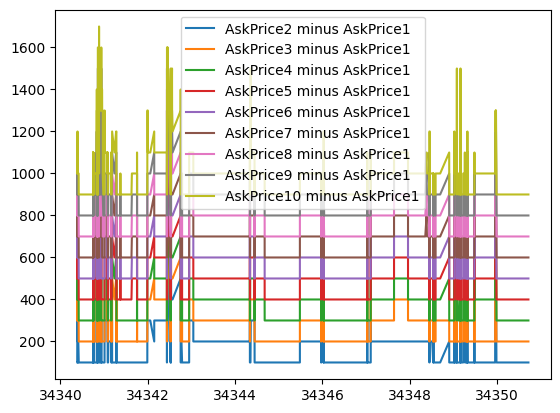

In [61]:

ob_AP2_minus_ob_AP1 = ob_AP2 - ob_AP1
ob_AP3_minus_ob_AP1 = ob_AP3 - ob_AP1
ob_AP4_minus_ob_AP1 = ob_AP4 - ob_AP1
ob_AP5_minus_ob_AP1 = ob_AP5 - ob_AP1
ob_AP6_minus_ob_AP1 = ob_AP6 - ob_AP1
ob_AP7_minus_ob_AP1 = ob_AP7 - ob_AP1
ob_AP8_minus_ob_AP1 = ob_AP8 - ob_AP1
ob_AP9_minus_ob_AP1 = ob_AP9 - ob_AP1
ob_AP10_minus_ob_AP1 = ob_AP10 - ob_AP1

i_min = 57000 #55000
i_max = 60000 # 65000
plt.plot(m_timestamps[i_min:i_max], ob_AP2_minus_ob_AP1[i_min:i_max], label = "AskPrice2 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP3_minus_ob_AP1[i_min:i_max], label = "AskPrice3 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP4_minus_ob_AP1[i_min:i_max], label = "AskPrice4 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP5_minus_ob_AP1[i_min:i_max], label = "AskPrice5 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP6_minus_ob_AP1[i_min:i_max], label = "AskPrice6 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP7_minus_ob_AP1[i_min:i_max], label = "AskPrice7 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP8_minus_ob_AP1[i_min:i_max], label = "AskPrice8 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP9_minus_ob_AP1[i_min:i_max], label = "AskPrice9 minus AskPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_AP10_minus_ob_AP1[i_min:i_max], label = "AskPrice10 minus AskPrice1")
plt.legend()
plt.show()

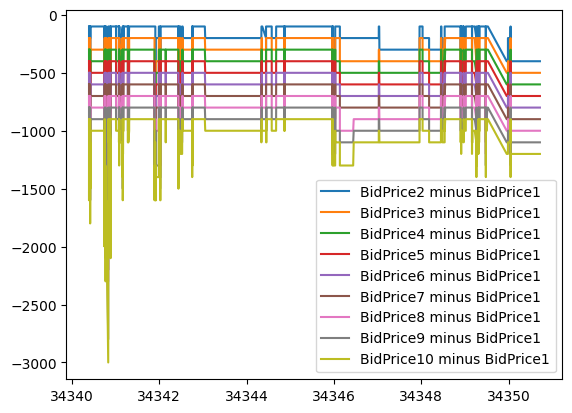

In [62]:
ob_BP2_minus_ob_BP1 = ob_BP2 - ob_BP1
ob_BP3_minus_ob_BP1 = ob_BP3 - ob_BP1
ob_BP4_minus_ob_BP1 = ob_BP4 - ob_BP1
ob_BP5_minus_ob_BP1 = ob_BP5 - ob_BP1
ob_BP6_minus_ob_BP1 = ob_BP6 - ob_BP1
ob_BP7_minus_ob_BP1 = ob_BP7 - ob_BP1
ob_BP8_minus_ob_BP1 = ob_BP8 - ob_BP1
ob_BP9_minus_ob_BP1 = ob_BP9 - ob_BP1
ob_BP10_minus_ob_BP1 = ob_BP10 - ob_BP1

i_min = 57000 #55000
i_max = 60000 # 65000
plt.plot(m_timestamps[i_min:i_max], ob_BP2_minus_ob_BP1[i_min:i_max], label = "BidPrice2 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP3_minus_ob_BP1[i_min:i_max], label = "BidPrice3 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP4_minus_ob_BP1[i_min:i_max], label = "BidPrice4 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP5_minus_ob_BP1[i_min:i_max], label = "BidPrice5 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP6_minus_ob_BP1[i_min:i_max], label = "BidPrice6 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP7_minus_ob_BP1[i_min:i_max], label = "BidPrice7 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP8_minus_ob_BP1[i_min:i_max], label = "BidPrice8 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP9_minus_ob_BP1[i_min:i_max], label = "BidPrice9 minus BidPrice1")
plt.plot(m_timestamps[i_min:i_max], ob_BP10_minus_ob_BP1[i_min:i_max], label = "BidPrice10 minus BidPrice1")
plt.legend()
plt.show()

In [33]:
ob_AS1 = df_ob['AskSize1']
ob_BS1 = df_ob['BidSize1']

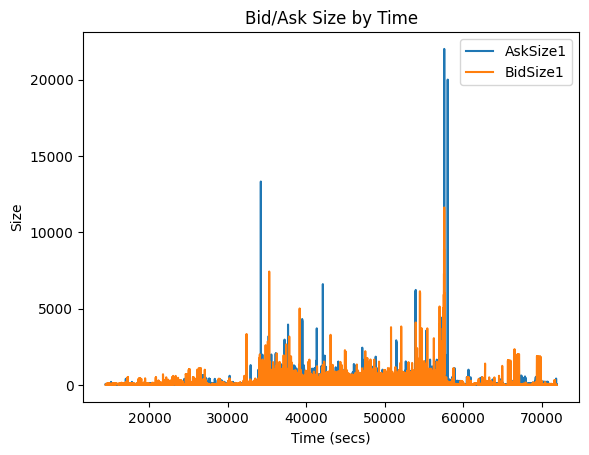

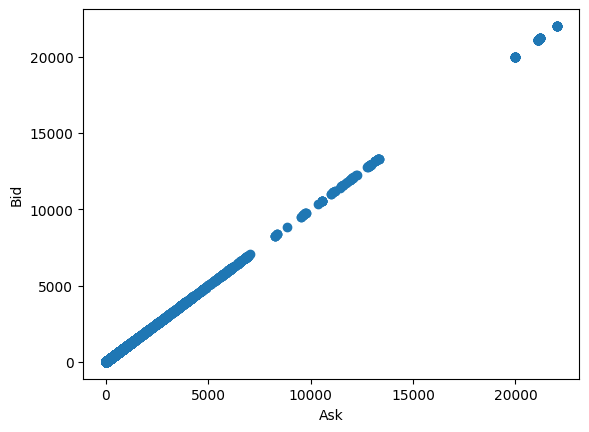

In [34]:
k = 100

plt.plot(m_timestamps[k:-k], ob_AS1[k:-k], label = "AskSize1")
plt.plot(m_timestamps[k:-k], ob_BS1[k:-k], label = "BidSize1")
plt.xlabel('Time (secs)')
plt.ylabel('Size')
plt.legend()
plt.title('Bid/Ask Size by Time')
plt.show()

plt.scatter(ob_AS1[k:-k], ob_AS1[k:-k])
plt.xlabel("Ask")
plt.ylabel("Bid")
plt.show()

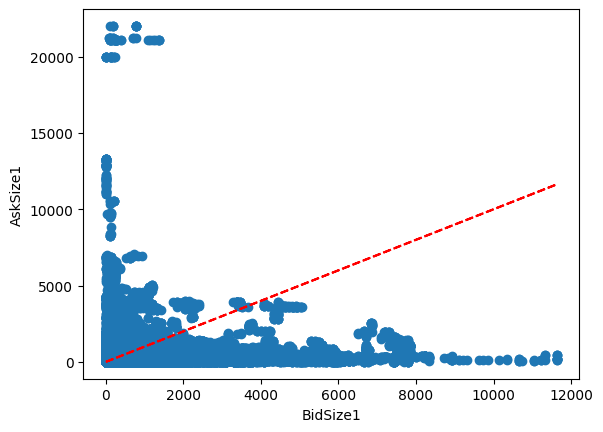

In [35]:
plt.plot(ob_BS1[k:-k], ob_BS1[k:-k], color = "red", linestyle = "--")
plt.scatter(ob_BS1[k:-k], ob_AS1[k:-k])
plt.xlabel("BidSize1")
plt.ylabel("AskSize1")
plt.show()

In [36]:
df_ob["ratio_AS1_BS1"] = df_ob["AskSize1"] / (df_ob["AskSize1"] + df_ob["BidSize1"])

In [37]:
df_ob["cum_AskSize_1_2"] = df_ob["AskSize1"] + df_ob["AskSize2"]
df_ob["cum_AskSize_1_3"] = df_ob["cum_AskSize_1_2"] + df_ob["AskSize3"]
df_ob["cum_AskSize_1_4"] = df_ob["cum_AskSize_1_3"] + df_ob["AskSize4"]
df_ob["cum_AskSize_1_5"] = df_ob["cum_AskSize_1_4"] + df_ob["AskSize5"]
df_ob["cum_AskSize_1_6"] = df_ob["cum_AskSize_1_5"] + df_ob["AskSize6"]
df_ob["cum_AskSize_1_7"] = df_ob["cum_AskSize_1_6"] + df_ob["AskSize7"]
df_ob["cum_AskSize_1_8"] = df_ob["cum_AskSize_1_7"] + df_ob["AskSize8"]
df_ob["cum_AskSize_1_9"] = df_ob["cum_AskSize_1_8"] + df_ob["AskSize9"]
df_ob["cum_AskSize_1_10"] = df_ob["cum_AskSize_1_9"] + df_ob["AskSize10"]

In [38]:
df_ob["cum_BidSize_1_2"] = df_ob["BidSize1"] + df_ob["BidSize2"]
df_ob["cum_BidSize_1_3"] = df_ob["cum_BidSize_1_2"] + df_ob["BidSize3"]
df_ob["cum_BidSize_1_4"] = df_ob["cum_BidSize_1_3"] + df_ob["BidSize4"]
df_ob["cum_BidSize_1_5"] = df_ob["cum_BidSize_1_4"] + df_ob["BidSize5"]
df_ob["cum_BidSize_1_6"] = df_ob["cum_BidSize_1_5"] + df_ob["BidSize6"]
df_ob["cum_BidSize_1_7"] = df_ob["cum_BidSize_1_6"] + df_ob["BidSize7"]
df_ob["cum_BidSize_1_8"] = df_ob["cum_BidSize_1_7"] + df_ob["BidSize8"]
df_ob["cum_BidSize_1_9"] = df_ob["cum_BidSize_1_8"] + df_ob["BidSize9"]
df_ob["cum_BidSize_1_10"] = df_ob["cum_BidSize_1_9"] + df_ob["BidSize10"]

In [39]:
df_ob["ratio_AS1_BS1"] = df_ob["AskSize1"] / (df_ob["AskSize1"] + df_ob["BidSize1"])

df_ob["ratio_cum_AS_1_2_BS_1_2"] = df_ob["cum_AskSize_1_2"] / (df_ob["cum_AskSize_1_2"] + df_ob["cum_BidSize_1_2"])
df_ob["ratio_cum_AS_1_3_BS_1_3"] = df_ob["cum_AskSize_1_3"] / (df_ob["cum_AskSize_1_3"] + df_ob["cum_BidSize_1_3"])
df_ob["ratio_cum_AS_1_4_BS_1_4"] = df_ob["cum_AskSize_1_4"] / (df_ob["cum_AskSize_1_4"] + df_ob["cum_BidSize_1_4"])
df_ob["ratio_cum_AS_1_5_BS_1_5"] = df_ob["cum_AskSize_1_5"] / (df_ob["cum_AskSize_1_5"] + df_ob["cum_BidSize_1_5"])
df_ob["ratio_cum_AS_1_6_BS_1_6"] = df_ob["cum_AskSize_1_6"] / (df_ob["cum_AskSize_1_6"] + df_ob["cum_BidSize_1_6"])
df_ob["ratio_cum_AS_1_7_BS_1_7"] = df_ob["cum_AskSize_1_7"] / (df_ob["cum_AskSize_1_7"] + df_ob["cum_BidSize_1_7"])
df_ob["ratio_cum_AS_1_8_BS_1_8"] = df_ob["cum_AskSize_1_8"] / (df_ob["cum_AskSize_1_8"] + df_ob["cum_BidSize_1_8"])
df_ob["ratio_cum_AS_1_9_BS_1_9"] = df_ob["cum_AskSize_1_9"] / (df_ob["cum_AskSize_1_9"] + df_ob["cum_BidSize_1_9"])
df_ob["ratio_cum_AS_1_10_BS_1_10"] = df_ob["cum_AskSize_1_10"] / (df_ob["cum_AskSize_1_10"] + df_ob["cum_BidSize_1_10"])

In [40]:
ob_ratio_AS1_BS1 = df_ob["ratio_AS1_BS1"]

ob_ratio_cum_AS_1_2_BS_1_2 = df_ob["ratio_cum_AS_1_2_BS_1_2"]
ob_ratio_cum_AS_1_3_BS_1_3 = df_ob["ratio_cum_AS_1_3_BS_1_3"]
ob_ratio_cum_AS_1_4_BS_1_4 = df_ob["ratio_cum_AS_1_4_BS_1_4"]
ob_ratio_cum_AS_1_5_BS_1_5 = df_ob["ratio_cum_AS_1_5_BS_1_5"]
ob_ratio_cum_AS_1_6_BS_1_6 = df_ob["ratio_cum_AS_1_6_BS_1_6"]
ob_ratio_cum_AS_1_7_BS_1_7 = df_ob["ratio_cum_AS_1_7_BS_1_7"]
ob_ratio_cum_AS_1_8_BS_1_8 = df_ob["ratio_cum_AS_1_8_BS_1_8"]
ob_ratio_cum_AS_1_9_BS_1_9 = df_ob["ratio_cum_AS_1_9_BS_1_9"]
ob_ratio_cum_AS_1_10_BS_1_10 = df_ob["ratio_cum_AS_1_10_BS_1_10"]

In [42]:
ob_ratio_AS1_BS1 = df_ob["ratio_AS1_BS1"]

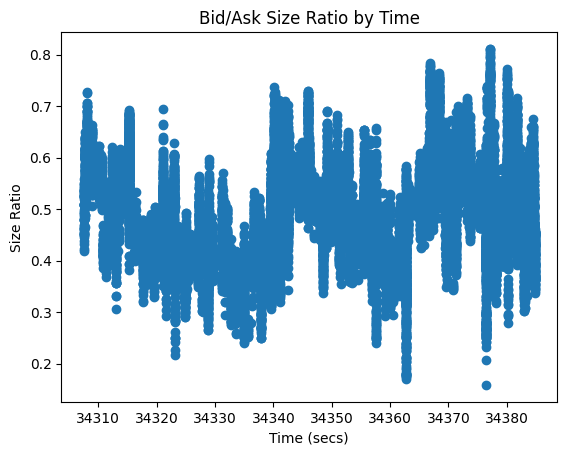

In [41]:
k = 100

i_min = 50000
i_max = 70000

plt.scatter(m_timestamps.iloc[i_min:i_max], ob_ratio_cum_AS_1_10_BS_1_10.iloc[i_min:i_max]) #, label = "AskSize1")
#plt.plot(m_timestamps[k:-k], ob_BS1[k:-k], label = "BidSize1")
plt.xlabel('Time (secs)')
plt.ylabel('Size Ratio')
#plt.legend()
plt.title('Bid/Ask Size Ratio by Time')
plt.show()

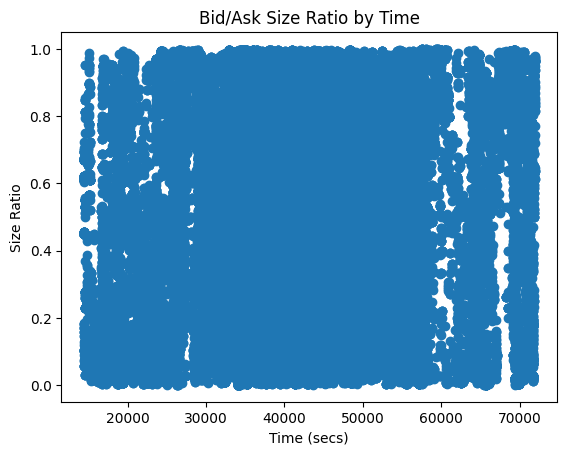

In [42]:
k = 100

plt.scatter(m_timestamps[k:-k], ob_ratio_cum_AS_1_2_BS_1_2[k:-k]) #, label = "AskSize1")
#plt.plot(m_timestamps[k:-k], ob_BS1[k:-k], label = "BidSize1")
plt.xlabel('Time (secs)')
plt.ylabel('Size Ratio')
#plt.legend()
plt.title('Bid/Ask Size Ratio by Time')
plt.show()

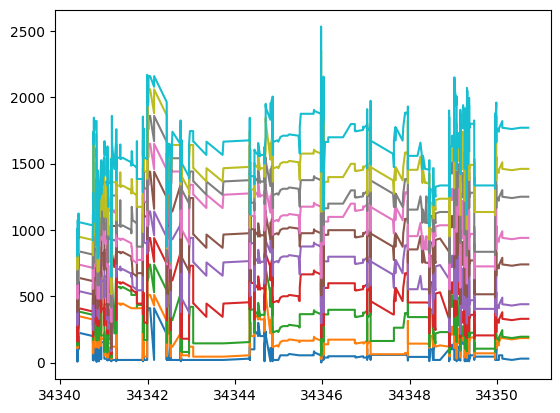

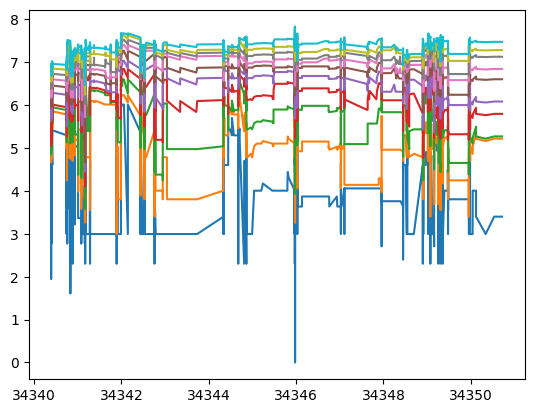

In [45]:

cum_ob_AS1_AS1 = df_ob["AskSize1"]
cum_ob_AS1_AS2 = df_ob["cum_AskSize_1_2"] 
cum_ob_AS1_AS3 = df_ob["cum_AskSize_1_3"]
cum_ob_AS1_AS4 = df_ob["cum_AskSize_1_4"]
cum_ob_AS1_AS5 = df_ob["cum_AskSize_1_5"]
cum_ob_AS1_AS6 = df_ob["cum_AskSize_1_6"]
cum_ob_AS1_AS7 = df_ob["cum_AskSize_1_7"]
cum_ob_AS1_AS8 = df_ob["cum_AskSize_1_8"]
cum_ob_AS1_AS9 = df_ob["cum_AskSize_1_9"]
cum_ob_AS1_AS10 = df_ob["cum_AskSize_1_10"]

log_cum_ob_AS1_AS1 = this_vec_log(cum_ob_AS1_AS1)
log_cum_ob_AS1_AS2 = this_vec_log(cum_ob_AS1_AS2)
log_cum_ob_AS1_AS3 = this_vec_log(cum_ob_AS1_AS3)
log_cum_ob_AS1_AS4 = this_vec_log(cum_ob_AS1_AS4)
log_cum_ob_AS1_AS5 = this_vec_log(cum_ob_AS1_AS5)
log_cum_ob_AS1_AS6 = this_vec_log(cum_ob_AS1_AS6)
log_cum_ob_AS1_AS7 = this_vec_log(cum_ob_AS1_AS7)
log_cum_ob_AS1_AS8 = this_vec_log(cum_ob_AS1_AS8)
log_cum_ob_AS1_AS9 = this_vec_log(cum_ob_AS1_AS9)
log_cum_ob_AS1_AS10 = this_vec_log(cum_ob_AS1_AS10)

i_min = 57000
i_max = 60000

plt.plot(m_timestamps.iloc[i_min:i_max], cum_ob_AS1_AS1[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], cum_ob_AS1_AS2[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], cum_ob_AS1_AS3[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], cum_ob_AS1_AS4[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], cum_ob_AS1_AS5[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], cum_ob_AS1_AS6[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], cum_ob_AS1_AS7[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], cum_ob_AS1_AS8[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], cum_ob_AS1_AS9[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], cum_ob_AS1_AS10[i_min:i_max])
plt.show()

plt.plot(m_timestamps.iloc[i_min:i_max], log_cum_ob_AS1_AS1[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], log_cum_ob_AS1_AS2[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], log_cum_ob_AS1_AS3[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], log_cum_ob_AS1_AS4[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], log_cum_ob_AS1_AS5[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], log_cum_ob_AS1_AS6[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], log_cum_ob_AS1_AS7[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], log_cum_ob_AS1_AS8[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], log_cum_ob_AS1_AS9[i_min:i_max])
plt.plot(m_timestamps.iloc[i_min:i_max], log_cum_ob_AS1_AS10[i_min:i_max])
plt.show()

In [44]:
import math

def log_abs(x):
    eps = 1e-6
    return math.log(max(eps, abs(x)))

# Apply the function using np.vectorize
this_vec_log_abs = np.vectorize(log_abs)

def floored_log(x):
    eps = 1e-6
    return math.log(max(eps, x))

# Apply the function using np.vectorize
this_vec_log = np.vectorize(floored_log)

In [46]:
print(log_abs(10.0))
print(log_abs(-10.0))
print(log_abs(0.000000001))
print(log_abs(-0.000000001))

xx = np.array([10.0, -10.0, 0.001, -0.001, 0.0000000001, -0.0000000001])

print(this_vec_log_abs(xx))
print(this_vec_log(xx))

2.302585092994046
2.302585092994046
-13.815510557964274
-13.815510557964274
[  2.30258509   2.30258509  -6.90775528  -6.90775528 -13.81551056
 -13.81551056]
[  2.30258509 -13.81551056  -6.90775528 -13.81551056 -13.81551056
 -13.81551056]


In [47]:
def expw_z_score(this_array : np.ndarray, final_scaling : float = 0.01, verbose=False) -> tuple:
    """
    exponentially-weighted z-score of this_array[0]
    with exponential weighting of this_array[i] given by lambda^i
    so [0] is the most recent data, and [len(this_array)-1] the oldest.
    """
    n = len(this_array)
    scale_factor = math.exp( math.log(final_scaling) / (n - 1.0))
    these_weights = scale_factor ** np.arange(n)
    total_weight = np.sum(these_weights)
    expw_mean = np.sum(this_array * these_weights) / total_weight
    demeaned = this_array - expw_mean
    expw_var = np.sum(demeaned * demeaned) / total_weight
    expw_std = math.sqrt(expw_var)
    expw_z_scores = (this_array - expw_mean) / expw_std

    if verbose:
        return these_weights, expw_mean, demeaned, expw_var, expw_std, expw_z_scores
    else:
        return expw_z_scores[0]

# Apply the function using np.vectorize
#vec_expw_z_score = np.vectorize(expw_z_score)

In [50]:
xx = np.array([1.0, 1.0, 1.0, 1.0, 1.0, 1.0])
xx = np.array([1.0, 2.0, 1.0, 2.0, 1.0, 2.0])
print(expw_z_score(xx))
xx = np.array([2.0, 1.0, 2.0, 1.0, 2.0, 1.0])
print(expw_z_score(xx))

-0.27470563412032967
0.2747056341203304


In [59]:
N = 1000
xx = np.ones(N)
xx[0] = 2.0
print(expw_z_score(xx))

xx[0] = 0.5
print(expw_z_score(xx))

xx[0] = 1.01
print(expw_z_score(xx))

xx[0] = -1.01
print(expw_z_score(xx))

xx[0] = 100.
print(expw_z_score(xx))

yy = np.random.normal(0,1,N)
yy[0] = 2.0
print(expw_z_score(yy))

yy[0] = -2.0
print(expw_z_score(yy))

yy[0] = 1.0
print(expw_z_score(yy))

14.514880121666026
-14.514880121666026
14.514880121666899
-14.514880121666028
14.514880121666035
0.9239486045422463
-0.9230713303347124
0.4631877379183224


len(xx) =  100
-20.84941905206564 -24.157214135232802 -10.49378616426351
-20.84941905206564 -24.157214135232802 -10.49378616426351


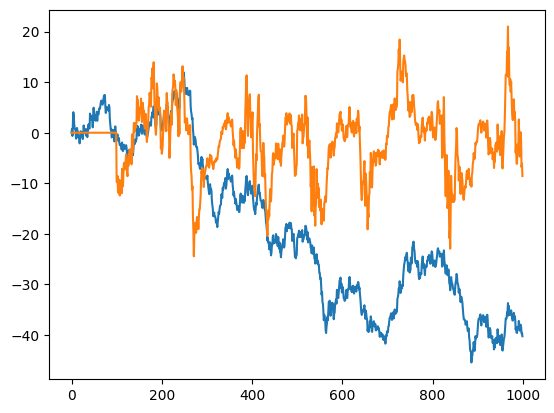

In [121]:
zz = np.random.normal(0,1,1000)
t_vals = np.arange(len(zz))
yy = np.cumsum(zz)
#yy = np.arange(0,1000)
t = 500
lookback = 100
xx = np.flip(yy[t - lookback + 1: t + 1])
#print(xx)
print("len(xx) = ", len(xx))
print(xx[0], xx[1], xx[-1])
print(yy[t], yy[t-1], yy[t-lookback+1]) #, yy[t-lookback])

z_score_vals = np.zeros(len(zz))
for tt in range(lookback, len(zz)):
    xx = np.flip(yy[tt - lookback + 1: tt + 1])
    z_score_vals[tt] = expw_z_score(xx)
    
    


plt.plot(t_vals, yy)
plt.plot(t_vals, 20.0 * z_score_vals)
plt.show()


In [72]:
x_vals = np.arange(100)
print(xx)
t = 50
lookback = 10
print(np.flip(x_vals[t - lookback : t]))


[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
[49 48 47 46 45 44 43 42 41 40]


In [94]:
initial_value = 10000
truncate_at = initial_value + 2000
x_vals = ob_BP1_minus_ob_AP1.values[initial_value:truncate_at]
print(type(x_vals))
print("len(x_vals) = ", len(x_vals))
lookback = 1000
z_score_vals = np.zeros(len(x_vals))
for t in np.arange(lookback, len(x_vals) - 1):
    these_vals = np.flip(x_vals[t - lookback : t + 1])
    #print("t = ", t, " len(these_vals) = ", len(these_vals))
    #print(these_vals)
    z_score = expw_z_score(these_vals)
    if t % 100 == 0:
        print(t, z_score)
    z_score_vals[t] = z_score

<class 'numpy.ndarray'>
len(x_vals) =  2000
1000 0.2630622857025468
1100 0.01152523201328538
1200 -0.29284358544920275
1300 0.05056277741767737
1400 0.4719519558097312
1500 0.44385513538130833
1600 -0.40995522505309456
1700 0.17315539115032502
1800 0.8581227590500581
1900 0.8889977947371416


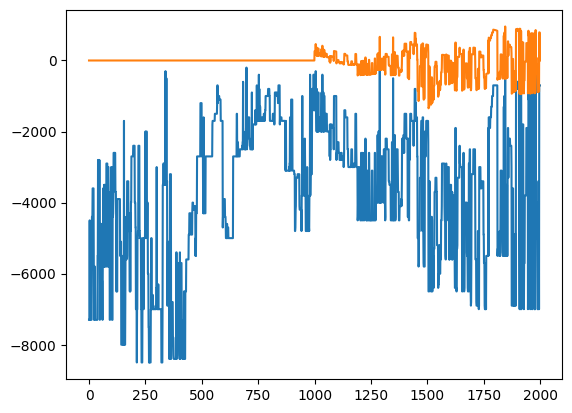

In [95]:
t_vals = np.arange(len(x_vals))
plt.plot(t_vals, x_vals)
plt.plot(t_vals, 1000.0 * z_score_vals)
plt.show()

In [101]:
def ff(this_array):
    return np.sum(this_array)

In [102]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view

N, k = 10, 3
xx = np.arange(N, dtype=float)

windows = sliding_window_view(xx, k)   # shape (N-k+1, k)

results = np.full(N, np.nan)           # entries 0..k-2 have no full window
results[k-1:] = ff(windows)             # row j  ->  results[j + k - 1]

In [103]:
print(xx)
print(windows)
print(results)

[0. 1. 2. 3. 4. 5. 6. 7. 8. 9.]
[[0. 1. 2.]
 [1. 2. 3.]
 [2. 3. 4.]
 [3. 4. 5.]
 [4. 5. 6.]
 [5. 6. 7.]
 [6. 7. 8.]
 [7. 8. 9.]]
[ nan  nan 108. 108. 108. 108. 108. 108. 108. 108.]


### Snapshot

In [45]:
k = 100
i = np.random.randint(k, len(m_price) - k)

# check these values:
# i = 1219915 # bid. Previous BidSize1 < updated BidSize1
# i = 33103
#i = 33102 # Message Price and updated AskPrice1 are the same
# i = 1707781 # bid. Previous BidSize5 > updated BidSize5
# i = 1194678 # bid. Previous BidSize2 > updated BidSize2
# i = 2020313 # ask. Previous AskSize1 < updated AskSize1
i = 72855 # new BidPrice1

print(i)

previous_ob = df_ob.iloc[i-1]
updated_ob = df_ob.iloc[i]
message = df_m.iloc[i]

num_errors = compare_ob_m_snapshots(previous_ob, updated_ob, message)
print("num_errors = ", num_errors)

72855


NameError: name 'compare_ob_m_snapshots' is not defined

In [46]:
def compare_ob_m_snapshots(previous_ob, updated_ob, message):

    num_errors = 0
    
    message_price = message["Price"]
    message_size = message["Size"]
    message_direction = message["Direction"]

    print("Message Price = ", message_price)
    print("Message Size = ", message_size)
    print("Message Direction = ", message_direction)

    max_n = 10
    
    for n in np.flip(np.arange(1,max_n + 1)):
        print_this = "Ask " + str(n) + " : "
        previous_ask_price_n = previous_ob["AskPrice" + str(n)]
        previous_ask_size_n = previous_ob["AskSize" + str(n)]
        updated_ask_price_n = updated_ob["AskPrice" + str(n)]
        updated_ask_size_n = updated_ob["AskSize" + str(n)]

        if message_price == updated_ask_price_n:
            print_this += "*** Message Price and updated AskPrice" + str(n) 
            print_this += " are the same, both equal to " + str(message_price) + "\n"
                        
        if message_price == previous_ask_price_n: 
            print_this += "*** Message Price and previous AskPrice" + str(n) 
            print_this += " are the same, both equal to " + str(message_price) + "\n"
        
        if previous_ask_price_n == updated_ask_price_n:
            print_this += "Previous and updated AskPrice" + str(n)
            print_this += " are the same, both equal to " + str(previous_ask_price_n)
            if previous_ask_size_n < updated_ask_size_n:
                print_this += "\n Previous AskSize" + str(n) + " < updated AskSize" + str(n)
                print_this += "\n Previous AskSize" + str(n) + " = " + str(previous_ask_size_n)
                print_this += ". Updated AskSize" + str(n) + " = " + str(updated_ask_size_n)
                actual_diff = updated_ask_size_n - previous_ask_size_n
                expected_diff = -1 * message_size * message_direction
                print_this += "\n Sanity check : actual diff = " + str(actual_diff)
                print_this += ", expected diff = " + str(expected_diff)
                if actual_diff == expected_diff:
                    print_this += "\n Sanity check : actual diff = expected diff, all good!"
                    print_this = "\n" + print_this + "\n"
                else:
                    print_this += "\n *** WEIRD : actual diff neq expected diff ***"
                    print_this = "\n" + print_this + "\n"
                    num_errors += 1
                
            if previous_ask_size_n == updated_ask_size_n:
                print_this += "\n Previous AskSize" + str(n) + " is equal to updated AskSize" + str(n)
                print_this += "\n Previous AskSize" + str(n) + " = " + str(previous_ask_size_n)
                print_this += ". Updated AskSize" + str(n) + " = " + str(updated_ask_size_n)
                    
            if previous_ask_size_n > updated_ask_size_n:
                print_this += "\n Previous AskSize" + str(n) + " > updated AskSize" + str(n)
                print_this += "\n Previous AskSize" + str(n) + " = " + str(previous_ask_size_n)
                print_this += ". Updated AskSize" + str(n) + " = " + str(updated_ask_size_n)
                actual_diff = updated_ask_size_n - previous_ask_size_n
                expected_diff = message_size * message_direction
                print_this += "\n Sanity check : actual diff = " + str(actual_diff)
                print_this += ", expected diff = " + str(expected_diff)
                if actual_diff == expected_diff:
                    print_this += "\n Sanity check : actual diff = expected diff, all good!"
                    print_this = "\n" + print_this + "\n"
                else:
                    print_this += "\n *** WEIRD : actual diff neq expected diff ***"
                    print_this = "\n" + print_this + "\n"
                    num_errors += 1
            
        if previous_ask_price_n < updated_ask_price_n:
            print_this += "Previous AskPrice" + str(n) + " < updated AskPrice" + str(n) 
            print_this += " : Previous = " + str(previous_ask_price_n) 
            print_this += ", updated = " + str(updated_ask_price_n)
            if n > 1:
                print_this += "\n *** Previous AskPrice" + str(n-1)  
                print_this += " = " + previous_ob["AskPrice" + str(n-1)]

        if previous_ask_price_n > updated_ask_price_n:
            print_this += "Previous AskPrice" + str(n) + " > updated AskPrice" + str(n)
            print_this += " : Previous = " + str(previous_ask_price_n) 
            print_this += ", updated = " + str(updated_ask_price_n)

        print(print_this)

    for n in np.arange(1,11):
        print_this = "Bid " + str(n) + " : "
        previous_bid_price_n = previous_ob["BidPrice" + str(n)]
        previous_bid_size_n = previous_ob["BidSize" + str(n)]
        updated_bid_price_n = updated_ob["BidPrice" + str(n)]
        updated_bid_size_n = updated_ob["BidSize" + str(n)]

        if message_price == updated_bid_price_n:
            print_this += "*** Message Price and updated BidPrice" + str(n) 
            print_this += " are the same, both equal to " + str(message_price) + "\n"
                        
        if message_price == previous_bid_price_n: 
            print_this += "*** Message Price and previous BidPrice" + str(n) 
            print_this += " are the same, both equal to " + str(message_price) + "\n"
        
        if previous_bid_price_n == updated_bid_price_n:
            print_this += "Previous and updated BidPrice" + str(n)
            print_this += " are the same, both equal to " + str(previous_bid_price_n)
            if previous_bid_size_n < updated_bid_size_n:
                print_this += "\n Previous BidSize" + str(n) + " < updated BidSize" + str(n)
                print_this += "\n Previous BidSize" + str(n) + " = " + str(previous_bid_size_n)
                print_this += ". Updated BidSize" + str(n) + " = " + str(updated_bid_size_n)
                actual_diff = updated_bid_size_n - previous_bid_size_n
                expected_diff = message_size * message_direction
                print_this += "\n Sanity check : actual diff = " + str(actual_diff)
                print_this += ", expected diff = " + str(expected_diff)
                if actual_diff == expected_diff:
                    print_this += "\n Sanity check : actual diff = expected diff, all good!"
                    print_this = "\n" + print_this + "\n"
                else:
                    print_this += "\n *** WEIRD : actual diff neq expected diff ***"
                    print_this = "\n" + print_this + "\n"
                    num_errors += 1
                
            if previous_bid_size_n == updated_bid_size_n:
                print_this += "\n Previous BidSize" + str(n) + " is equal to updated BidSize" + str(n)
                print_this += "\n Previous BidSize" + str(n) + " = " + str(previous_bid_size_n)
                print_this += ". Updated BidSize" + str(n) + " = " + str(updated_bid_size_n)
                    
            if previous_bid_size_n > updated_bid_size_n:
                print_this += "\n Previous BidSize" + str(n) + " > updated BidSize" + str(n)
                print_this += "\n Previous BidSize" + str(n) + " = " + str(previous_bid_size_n)
                print_this += ". Updated BidSize" + str(n) + " = " + str(updated_bid_size_n)
                actual_diff = updated_bid_size_n - previous_bid_size_n
                expected_diff = -1 * message_size * message_direction
                print_this += "\n Sanity check : actual diff = " + str(actual_diff)
                print_this += ", expected diff = " + str(expected_diff)
                if actual_diff == expected_diff:
                    print_this += "\n Sanity check : actual diff = expected diff, all good!"
                    print_this = "\n" + print_this + "\n"
                else:
                    print_this += "\n *** WEIRD : actual diff neq expected diff ***"
                    print_this = "\n" + print_this + "\n"
                    num_errors += 1
            
        if previous_bid_price_n < updated_bid_price_n:
            print_this += "Previous BidPrice < updated BidPrice : Previous = " 
            print_this += str(previous_bid_price_n) + ", updated = " + str(updated_bid_price_n)

        if previous_bid_price_n > updated_bid_price_n:
            print_this += "Previous BidPrice > updated BidPrice : Previous = "
            print_this += str(previous_bid_price_n) + ", updated = " + str(updated_bid_price_n)

        print(print_this)

    return num_errors

In [ ]:
#message_index 
sep="="*100
k = 100
i = np.random.randint(k, len(m_price) - k)

#i = 384043
i = 33102

print(i)
print(sep)
print(df_m.iloc[i])
print(sep)
print(i-1, "AskPrice1", df_ob.iloc[i-1]["AskPrice1"])
print(i-1, "AskSize1", df_ob.iloc[i-1]["AskSize1"])
print(i-1, "BidPrice1", df_ob.iloc[i-1]["BidPrice1"])
print(i-1, "BidSize1", df_ob.iloc[i-1]["BidSize1"])
#print(i-1, "BidPrice2", df_ob.iloc[i-1]["BidPrice2"])
#print(i-1, "BidSize2", df_ob.iloc[i-1]["BidSize2"])
#print(i-1, "BidPrice8", df_ob.iloc[i-1]["BidPrice8"])
#print(i-1, "BidSize8", df_ob.iloc[i-1]["BidSize8"])
print(sep)
print(i, "AskPrice1", df_ob.iloc[i]["AskPrice1"])
print(i, "AskSize1", df_ob.iloc[i]["AskSize1"])
print(i, "BidPrice1", df_ob.iloc[i]["BidPrice1"])
print(i, "BidSize1", df_ob.iloc[i]["BidSize1"])

print(sep)

message_Price = df_m.iloc[i]["Price"]
message_Size = df_m.iloc[i]["Size"]
message_Direction = df_m.iloc[i]["Direction"]
print("Message Price = ", message_Price)
print("Message Size = ", message_Size)
print("Message Direction = ", message_Direction)


print(sep)

for n in range(1,11):
    this_AskPrice_key = "AskPrice" + str(n)
    this_AskPrice = df_ob.iloc[i-1][this_AskPrice_key]
    if message_Price == this_AskPrice:
        this_AskSize_key = "AskSize" + str(n)
        print(i-1, this_AskPrice_key, this_AskPrice, this_AskSize_key, df_ob.iloc[i-1][this_AskSize_key])
        print(i, this_AskPrice_key, df_ob.iloc[i][this_AskPrice_key], this_AskSize_key, df_ob.iloc[i][this_AskSize_key])
        
for n in range(1,11):
    this_BidPrice_key = "BidPrice" + str(n)
    this_BidPrice = df_ob.iloc[i-1][this_BidPrice_key]
    if message_Price == this_BidPrice:
        this_BidSize_key = "BidSize" + str(n)
        print(i-1, this_BidPrice_key, this_BidPrice, this_BidSize_key, df_ob.iloc[i-1][this_BidSize_key])
        print(i, this_BidPrice_key, df_ob.iloc[i][this_BidPrice_key], this_BidSize_key, df_ob.iloc[i][this_BidSize_key])

In [ ]:

def OLD_compare_ob_m_snapshots(previous_ob, updated_ob, message):
    
    message_price = message["Price"]
    message_size = message["Size"]
    message_direction = message["Direction"]

    print("Message Price = ", message_price)
    print("Message Size = ", message_size)
    print("Message Direction = ", message_direction)

    max_n = 10
    
    for n in np.flip(np.arange(1,max_n + 1)):
        print_this = "Ask " + str(n) + " : "
        previous_ask_price_n = previous_ob["AskPrice" + str(n)]
        previous_ask_size_n = previous_ob["AskSize" + str(n)]
        updated_ask_price_n = updated_ob["AskPrice" + str(n)]
        updated_ask_size_n = updated_ob["AskSize" + str(n)]

        if message_price == updated_ask_price_n:
            print_this += "*** Message Price and updated AskPrice" + str(n) 
            print_this += " are the same, both equal to " + str(message_price) + "\n"
                        
        if message_price == previous_ask_price_n: 
            print_this += "*** Message Price and previous AskPrice" + str(n) 
            print_this += " are the same, both equal to " + str(message_price) + "\n"
        
        if previous_ask_price_n == updated_ask_price_n:
            print_this += "Previous and updated AskPrice" + str(n)
            print_this += " are the same, both equal to " + str(previous_ask_price_n)
            if previous_ask_size_n < updated_ask_size_n:
                print_this += "\n Previous AskSize" + str(n) + " < updated AskSize" + str(n)
                print_this += "\n Previous AskSize" + str(n) + " = " + str(previous_ask_size_n)
                print_this += "\n Updated AskSize" + str(n) + " = " + str(updated_ask_size_n)
                actual_diff = updated_ask_size_n - previous_ask_size_n
                expected_diff = -1 * message_size * message_direction
                print_this += "\n Sanity check : actual diff = " + str(actual_diff)
                print_this += "\n Sanity check : expected diff = " + str(expected_diff)
                if actual_diff == expected_diff:
                    print_this += "\n Sanity check : actual diff = expected diff, all good!"
                else:
                    print_this += "\n *** WEIRD : actual diff neq expected diff ***"
                
            if previous_ask_size_n == updated_ask_size_n:
                print_this += "\n Previous AskSize" + str(n) + " is equal to updated AskSize" + str(n)
                print_this += "\n Previous AskSize" + str(n) + " = " + str(previous_ask_size_n)
                print_this += "\n Updated AskSize" + str(n) + " = " + str(updated_ask_size_n)
                    
            if previous_ask_size_n > updated_ask_size_n:
                print_this += "\n Previous AskSize" + str(n) + " > updated AskSize" + str(n)
                print_this += "\n Previous AskSize" + str(n) + " = " + str(previous_ask_size_n)
                print_this += "\n Updated AskSize" + str(n) + " = " + str(updated_ask_size_n)
                actual_diff = updated_ask_size_n - previous_ask_size_n
                expected_diff = -1 * message_size * message_direction
                print_this += "\n Sanity check : actual diff = " + str(actual_diff)
                print_this += "\n Sanity check : expected diff = " + str(expected_diff)
                if actual_diff == expected_diff:
                    print_this += "\n Sanity check : actual diff = expected diff, all good!"
                else:
                    print_this += "\n *** WEIRD : actual diff neq expected diff ***"
            
        if previous_ask_price_n < updated_ask_price_n:
            print_this += "Previous AskPrice" + str(n) + " < updated AskPrice" + str(n) 
            print_this += " : Previous = " + str(previous_ask_price_n) + ", updated = " + str(updated_ask_price_n)

        if previous_ask_price_n > updated_ask_price_n:
            print_this += "Previous AskPrice" + str(n) + " > updated AskPrice" + str(n)
            print_this += " : Previous = " + str(previous_ask_price_n) + ", updated = " + str(updated_ask_price_n)

        print(print_this)

    for n in np.arange(1,11):
        print_this = "Bid " + str(n) + " : "
        previous_bid_price_n = previous_ob["BidPrice" + str(n)]
        previous_bid_size_n = previous_ob["BidSize" + str(n)]
        updated_bid_price_n = updated_ob["BidPrice" + str(n)]
        updated_bid_size_n = updated_ob["BidSize" + str(n)]
        
        if previous_bid_price_n == updated_bid_price_n:
            print_this += "Previous and updated BidPrice are the same, both equal to " 
            print_this += str(previous_bid_price_n)
            
        if previous_bid_price_n < updated_bid_price_n:
            print_this += "Previous BidPrice < updated BidPrice : Previous = " 
            print_this += str(previous_bid_price_n) + ", updated = " + str(updated_bid_price_n)

        if previous_bid_price_n > updated_bid_price_n:
            print_this += "Previous BidPrice > updated BidPrice : Previous = "
            print_this += str(previous_bid_price_n) + ", updated = " + str(updated_bid_price_n)

        print(print_this)

In [ ]:
for i in np.flip(np.arange(1,11)):#.flip():
    print(i)